# Практическое занятие № 6 — вариант 7

## 1. Исходные данные

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# вариант 7
y = np.array([134, 130, 128, 126, 122, 120, 117, 112, 108, 105], dtype=float)
t = np.arange(1, len(y) + 1)

print(pd.DataFrame({'Год': t, 'Выпуск продукции': y}).to_string(index=False))

 Год  Выпуск продукции
   1             134.0
   2             130.0
   3             128.0
   4             126.0
   5             122.0
   6             120.0
   7             117.0
   8             112.0
   9             108.0
  10             105.0


## 2. График исходного временного ряда

По графику проверяем наличие **тренда** (общего направления изменения) и возможной **сезонности** (повторяющихся колебаний через одинаковые интервалы).

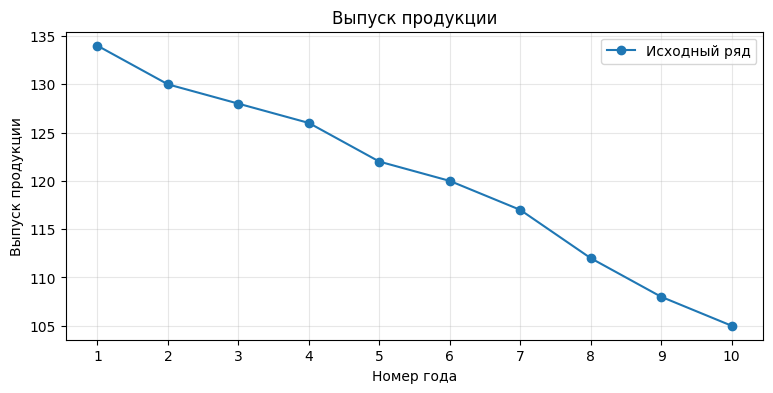

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(t, y, 'o-', label='Исходный ряд')
plt.xticks(t)
plt.xlabel('Номер года')
plt.ylabel('Выпуск продукции')
plt.title('Выпуск продукции')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 3. Двойное экспоненциальное сглаживание

- Уровень $l_t$ — текущая сглаженная величина выпуска.
- Тренд $b_t$ — сглаженное изменение уровня за один год.
- $\alpha$ — вес нового наблюдения при обновлении уровня.
- $\beta$ — вес нового изменения при обновлении тренда.


$$l_t=\alpha y_t+(1-\alpha)(l_{t-1}+b_{t-1}),$$

$$b_t=\beta(l_t-l_{t-1})+(1-\beta)b_{t-1},$$

$$\hat y_{t+1}=l_t+b_t.$$

Для начала возьмём $l_2=y_2=130$, $b_2=y_2-y_1=130-134=-4$. С 3-го года получаем однократный прогноз перед обновлением по факту. Таким образом, ошибки доступны для годов 3–10 (8 ошибок).

In [ ]:
def double_exponential_smoothing(series, alpha, beta):
    level, trend = series[1], series[1] - series[0]
    fitted = []
    levels = [level]
    trends = [trend]

    for n in range(2, len(series)):
        predicted = level + trend     # прогноз на очередной год ДО получения факта
        fitted.append(predicted)

        value = series[n]
        last_level, level = level, alpha * value + (1 - alpha) * (level + trend)
        trend = beta * (level - last_level) + (1 - beta) * trend
        levels.append(level)
        trends.append(trend)

    return np.array(fitted), level, trend, np.array(levels), np.array(trends)

fitted_example, level_example, trend_example, _, _ = double_exponential_smoothing(y, 0.9, 0.9)
print('При α = 0.9, β = 0.9:')
print(f'Прогноз на 3-й год: {fitted_example[0]:.2f}; факт: {y[2]:.2f}')
print(f'Прогноз на 11-й год: {level_example + trend_example:.2f}')

При α = 0.9, β = 0.9:
Прогноз на 3-й год: 126.00; факт: 128.00
Прогноз на 11-й год: 101.65


## 4. Сравнение коэффициентов $\alpha$ и $\beta$

Сравним четыре пары коэффициентов: $\alpha\in\{0{,}9;\ 0{,}02\}$, $\beta\in\{0{,}9;\ 0{,}02\}$ и построим графики. Большие коэффициенты сильнее учитывают последние данные, малые дают более плавные оценки.

Для сравнения рассчитаем MSE (средний квадрат ошибки) и MAE (средний модуль ошибки) по 8 одношаговым прогнозам на годы 3–10. Здесь шаг прогноза — один год

Меньшая ошибка означает лучшую подгонку к этим наблюдениям.

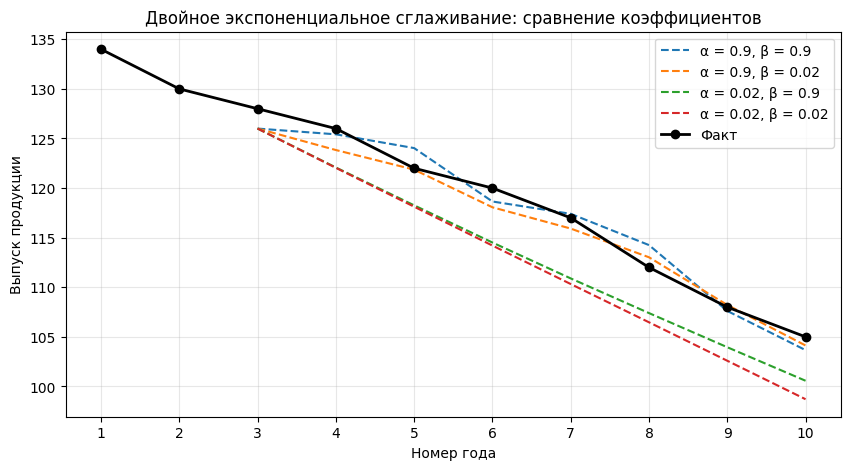

   α    β     MSE    MAE
0.90 0.90  2.1839 1.2933
0.90 0.02  1.9340 1.1790
0.02 0.90 19.7450 4.2918
0.02 0.02 26.5319 4.9421


In [ ]:
# Сравнение четырёх сочетаний
results = []
plt.figure(figsize=(10, 5))

for alpha in [0.9, 0.02]:
    for beta in [0.9, 0.02]:
        fitted, level, trend, _, _ = double_exponential_smoothing(y, alpha, beta)
        errors = y[2:] - fitted
        mse = np.mean(errors ** 2)
        mae = np.mean(np.abs(errors))
        results.append((alpha, beta, mse, mae))
        plt.plot(t[2:], fitted, '--', label=f'α = {alpha}, β = {beta}')

plt.plot(t, y, 'ko-', linewidth=2, label='Факт')
plt.xticks(t)
plt.xlabel('Номер года')
plt.ylabel('Выпуск продукции')
plt.title('Двойное экспоненциальное сглаживание: сравнение коэффициентов')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

comparison = pd.DataFrame(results, columns=['α', 'β', 'MSE', 'MAE'])
print(comparison.round(4).to_string(index=False))

## 5. Выбранная модель и прогноз на 11-й год

Выберем пару с наименьшей MSE.

С последнего известного года прогнозируем на один год вперёд по формуле $\hat y_{11}=l_{10}+b_{10}$. Фактическое значение 11-го года не дано, поэтому ошибку будущего прогноза определить нельзя.

Выбраны α = 0.9, β = 0.02 (минимальная MSE )
MSE = 1.9340; MAE = 1.1790
Уровень на конец 10-го года = 104.9131
Тренд на конец 10-го года = -3.8748
Прогноз на 11-й год = 101.04

Факты и одношаговые прогнозы для годов 3–10:
 Год  Факт  Прогноз  Ошибка
   3 128.0   126.00    2.00
   4 126.0   123.84    2.16
   5 122.0   121.86    0.14
   6 120.0   118.06    1.94
   7 117.0   115.92    1.08
   8 112.0   113.02   -1.02
   9 108.0   108.22   -0.22
  10 105.0   104.13    0.87


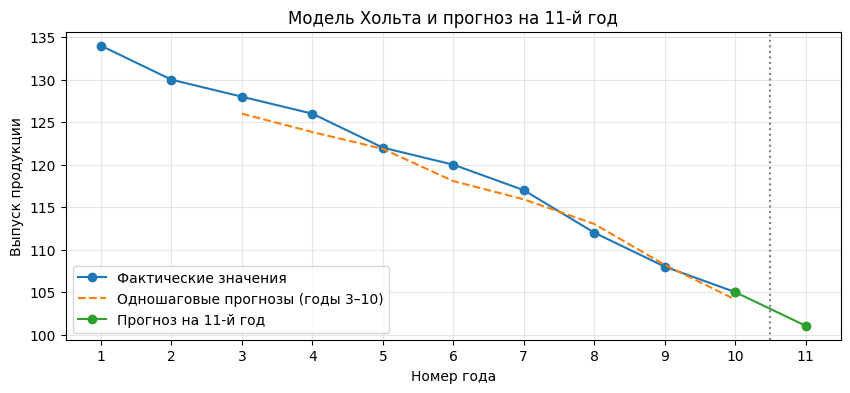

In [ ]:
best = min(results, key=lambda row: row[2])
alpha, beta, best_mse, best_mae = best
fitted, level, trend, levels, trends = double_exponential_smoothing(y, alpha, beta)
forecast_11 = level + trend

print(f'Выбраны α = {alpha}, β = {beta} (минимальная MSE )')
print(f'MSE = {best_mse:.4f}; MAE = {best_mae:.4f}')
print(f'Уровень на конец 10-го года = {level:.4f}')
print(f'Тренд на конец 10-го года = {trend:.4f}')
print(f'Прогноз на 11-й год = {forecast_11:.2f}')

print('\nФакты и одношаговые прогнозы для годов 3–10:')
print(pd.DataFrame({
    'Год': t[2:],
    'Факт': y[2:],
    'Прогноз': np.round(fitted, 2),
    'Ошибка': np.round(y[2:] - fitted, 2)
}).to_string(index=False))

plt.figure(figsize=(10, 4))
plt.plot(t, y, 'o-', label='Фактические значения')
plt.plot(t[2:], fitted, '--', label='Одношаговые прогнозы (годы 3–10)')
plt.plot([10, 11], [y[-1], forecast_11], 'o-', label='Прогноз на 11-й год')
plt.axvline(10.5, linestyle=':', color='gray')
plt.xticks(np.arange(1, 12))
plt.xlabel('Номер года')
plt.ylabel('Выпуск продукции')
plt.title('Модель Хольта и прогноз на 11-й год')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 6. Вывод

По варианту 7 исходный выпуск снижается с 134 до 105 за 10 лет. По коду двойного экспоненциального сглаживания построена модель с уровнем и трендом. Сравнены четыре сочетания коэффициентов; рассчитаны одношаговые прогнозы за годы 3–10 и ошибки MSE, MAE; получен прогноз на 11-й год.